# Course 1 - Modul 4: Statistical Inference, Hypothesis Testing, and Machine Learning Modeling
**Mata Kuliah**: Data Mining  
**Kode Modul**: `c1-m4` (Course 1 - Module 4)  
**Topik Utama**: Inferensi Statistik, Distribusi Probabilitas, Paradigma Frequentist vs Bayesian, Pengujian Hipotesis (T-Test, Chi-Square, ANOVA/F-Test, Bonferroni), dan Implementasi Model Prediksi Terbaik (Baseline vs Random Forest vs XGBoost vs Ensemble).

---

## 1. Pendahuluan & Ringkasan Pembelajaran
Modul 4 merupakan puncak dari rangkaian Course 1 yang menghubungkan dasar-dasar inferensi statistik dengan pemodelan prediktif data mining tingkat lanjut:
1. **Inferensi Statistik vs Estimasi**: Memahami proses pembentukan data (*data-generating process*), model parametrik vs non-parametrik.
2. **Distribusi Probabilitas**: Normal, Uniform, Binomial, Poisson, serta pengujian normalitas data riil.
3. **Frequentist vs Bayesian Paradigms**: Simulasi pelemparan koin (sesuai materi acuan video perkuliahan), penggabungan *Prior Beliefs*, *Likelihood*, dan kalkulasi *Posterior Distribution*.
4. **Framework Pengujian Hipotesis**:
   - Hipotesis Nol ($H_0$) vs Alternatif ($H_1$).
   - Kesalahan Tipe I (False Positive / $\alpha$) dan Kesalahan Tipe II (False Negative / $\beta$).
   - Tingkat signifikansi, p-value, dan daerah penolakan (*rejection region*).
   - *Independent Two-Sample T-test* dan uji non-parametrik *Mann-Whitney U*.
   - *Chi-Square Test of Independence* pada variabel kategorikal bisnis churn.
   - *F-statistic* pada regresi linear via `statsmodels` (menguji apakah penambahan fitur signifikan dibanding model konstan).
   - Masalah pengujian jamak (*multiple testing*) dan koreksi *Bonferroni* ($\alpha / k$).
5. **Pemodelan Machine Learning Terbaik ("Modifikasikan dengan Model Terbaik!")**:
   - Membangun pipeline terintegrasi (*Stratified Train-Test Split*, *ColumnTransformer*).
   - Komparasi 6 Algoritma:
     1. Baseline: *Logistic Regression*
     2. *Decision Tree Classifier*
     3. *Random Forest Classifier* (Tuned)
     4. *HistGradientBoosting Classifier*
     5. *XGBoost Classifier* (State-of-the-art Gradient Boosted Trees)
     6. *Voting Ensemble Classifier*
   - Evaluasi komprehensif: Akurasi, Presisi, Recall, F1-Score, ROC-AUC, Matriks Konfusi Heatmap, Kurva ROC & Precision-Recall, serta Feature Importance.


## 2. Statistical Foundations & Distribusi Probabilitas

Sebelum menguji hipotesis, kita perlu memahami distribusi data. Model parametrik berasumsi bahwa sampel ditarik dari distribusi teoritis tertentu (seperti Gaussian/Normal).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

print("Import modul statistik & machine learning berhasil!")


Import modul statistik & machine learning berhasil!


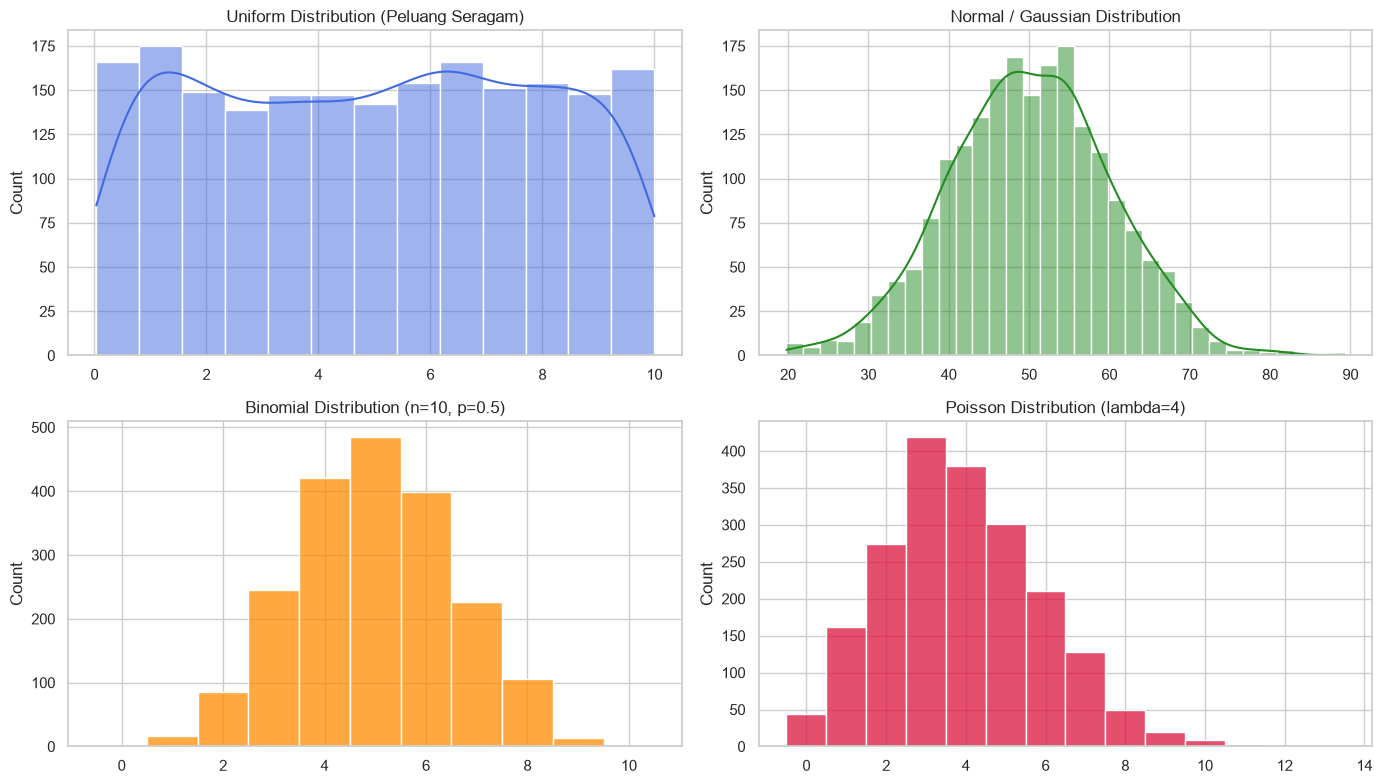

In [2]:
# Simulasi 4 Distribusi Probabilitas Umum (Sesuai Materi c1-m4(3).txt)
np.random.seed(42)
n_samples = 2000

dist_uniform = np.random.uniform(low=0, high=10, size=n_samples)
dist_normal = np.random.normal(loc=50, scale=10, size=n_samples)
dist_binomial = np.random.binomial(n=10, p=0.5, size=n_samples) # 10 lemparan koin
dist_poisson = np.random.poisson(lam=4, size=n_samples)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(dist_uniform, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title('Uniform Distribution (Peluang Seragam)')

sns.histplot(dist_normal, kde=True, ax=axes[0, 1], color='forestgreen')
axes[0, 1].set_title('Normal / Gaussian Distribution')

sns.histplot(dist_binomial, discrete=True, ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('Binomial Distribution (n=10, p=0.5)')

sns.histplot(dist_poisson, discrete=True, ax=axes[1, 1], color='crimson')
axes[1, 1].set_title('Poisson Distribution (lambda=4)')

plt.tight_layout()
plt.show()


## 3. Frequentist vs. Bayesian Paradigm: Simulasi Pelemparan Koin

Sesuai materi perkuliahan (`c1-m4(4).txt` s.d. `c1-m4(7).txt`):
- **Frequentist**: Probabilitas diartikan sebagai frekuensi relatif dalam jangka panjang dari percobaan yang berulang. Parameter populasi dianggap bernilai tetap (*fixed*).
- **Bayesian**: Probabilitas diartikan sebagai derajat keyakinan (*degree of belief*). Kita memulai dengan *Prior Distribution*, mengamati data (*Likelihood*), dan memperbarui keyakinan menjadi *Posterior Distribution* menggunakan Teorema Bayes:
  $$P(\theta | D) = \frac{P(D | \theta) \cdot P(\theta)}{P(D)}$$


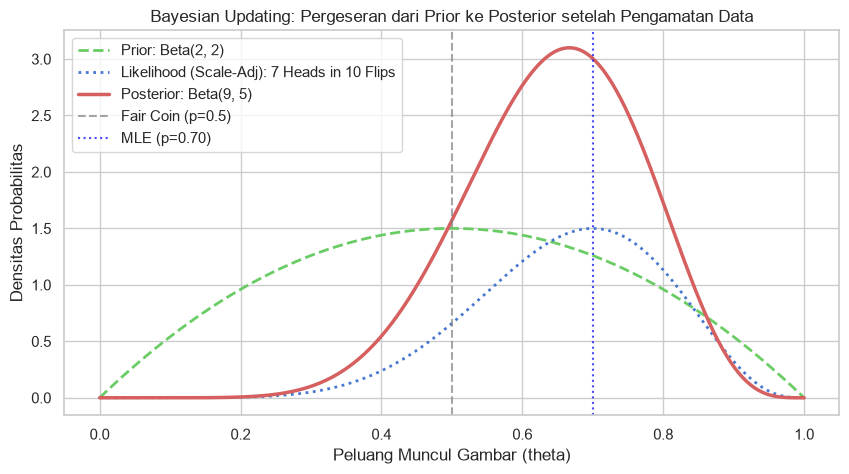

Frequentist MLE estimate: 0.70
Bayesian Posterior Mean estimate: 0.64


In [3]:
# Simulasi Bayesian Updating (Beta-Binomial Model)
# Kasus: Pelemparan koin 10 kali, diperoleh 7 sisi angka (heads)
flips = 10
heads = 7

# Parameter Prior: Beta(a, b) -> a=2, b=2 (prior simetris dengan sedikit keyakinan koin seimbang)
alpha_prior = 2
beta_prior = 2

# Parameter Posterior: Beta(a + heads, b + tails)
alpha_post = alpha_prior + heads
beta_post = beta_prior + (flips - heads)

theta = np.linspace(0, 1, 500)
prior_pdf = stats.beta.pdf(theta, alpha_prior, beta_prior)
likelihood = stats.binom.pmf(heads, flips, theta)
likelihood_scaled = likelihood / np.max(likelihood) * np.max(prior_pdf) # skala visual
posterior_pdf = stats.beta.pdf(theta, alpha_post, beta_post)

plt.figure(figsize=(10, 5))
plt.plot(theta, prior_pdf, 'g--', label=f'Prior: Beta({alpha_prior}, {beta_prior})', lw=2)
plt.plot(theta, likelihood_scaled, 'b:', label=f'Likelihood (Scale-Adj): {heads} Heads in {flips} Flips', lw=2)
plt.plot(theta, posterior_pdf, 'r-', label=f'Posterior: Beta({alpha_post}, {beta_post})', lw=2.5)

plt.axvline(0.5, color='gray', linestyle='--', alpha=0.7, label='Fair Coin (p=0.5)')
plt.axvline(heads/flips, color='blue', linestyle=':', alpha=0.7, label=f'MLE (p={heads/flips:.2f})')
plt.title('Bayesian Updating: Pergeseran dari Prior ke Posterior setelah Pengamatan Data', fontsize=12)
plt.xlabel('Peluang Muncul Gambar (theta)')
plt.ylabel('Densitas Probabilitas')
plt.legend()
plt.show()

print(f"Frequentist MLE estimate: {heads/flips:.2f}")
print(f"Bayesian Posterior Mean estimate: {alpha_post / (alpha_post + beta_post):.2f}")


## 4. Pengujian Hipotesis Statistik pada Kasus Bisnis Churn

Kita menguji beberapa hipotesis kunci pada dataset pelanggan telekomunikasi untuk menjawab pertanyaan bisnis:
1. **Uji Hipotesis 1 (T-Test Independen)**: Apakah ada perbedaan signifikan dalam tagihan bulanan (*MonthlyCharges*) antara pelanggan yang Churn vs Tidak Churn?
   - $H_0: \mu_{\text{churn}} = \mu_{\text{non-churn}}$
   - $H_1: \mu_{\text{churn}} \neq \mu_{\text{non-churn}}$
2. **Uji Hipotesis 2 (Mann-Whitney U Non-parametrik)**: Uji komparasi tanpa asumsi normalitas.
3. **Uji Hipotesis 3 (Chi-Square Test of Independence)**: Apakah status Churn independen dari Tipe Kontrak (*Contract*)?
   - $H_0$: Churn dan Tipe Kontrak independen (tidak berhubungan).
   - $H_1$: Terdapat asosiasi signifikan antara Kontrak dan Churn.
4. **Uji Hipotesis 4 (F-Statistic Regresi & Bonferroni Correction)**: Menguji signifikansi koefisien fitur pada model regresi linear dan mengoreksi risiko Kesalahan Tipe I menggunakan Bonferroni correction.


In [4]:
# Memuat dataset telco churn
df_telco = pd.read_csv('data/telco_customer_churn.csv')
df_telco['TotalCharges'] = pd.to_numeric(df_telco['TotalCharges'], errors='coerce')
df_telco['TotalCharges'].fillna(df_telco['TotalCharges'].median(), inplace=True)

# 4.1 Independent Two-Sample T-Test
charges_churn = df_telco[df_telco['Churn'] == 'Yes']['MonthlyCharges']
charges_nonchurn = df_telco[df_telco['Churn'] == 'No']['MonthlyCharges']

t_stat, p_val_t = stats.ttest_ind(charges_churn, charges_nonchurn, equal_var=False)
print("=== HASIL INDEPENDENT T-TEST ===")
print(f"Rata-rata Biaya Pelanggan Churn    : ${charges_churn.mean():.2f}")
print(f"Rata-rata Biaya Pelanggan Non-Churn: ${charges_nonchurn.mean():.2f}")
print(f"T-statistic : {t_stat:.4f}")
print(f"P-value     : {p_val_t:.4e}")
if p_val_t < 0.05:
    print("Keputusan   : TOLAK H0. Terdapat perbedaan signifikan secara statistik pada MonthlyCharges antara kedua grup!")
else:
    print("Keputusan   : GAGAL TOLAK H0.")


=== HASIL INDEPENDENT T-TEST ===
Rata-rata Biaya Pelanggan Churn    : $67.91
Rata-rata Biaya Pelanggan Non-Churn: $58.85
T-statistic : 8.2656
P-value     : 3.7506e-16
Keputusan   : TOLAK H0. Terdapat perbedaan signifikan secara statistik pada MonthlyCharges antara kedua grup!


In [5]:
# 4.2 Chi-Square Test of Independence (Contract vs Churn)
contingency_table = pd.crosstab(df_telco['Contract'], df_telco['Churn'])
print("Tabel Kontingensi (Contract vs Churn):")
display(contingency_table)

chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)
print("\n=== HASIL CHI-SQUARE TEST ===")
print(f"Chi2-statistic : {chi2_stat:.4f}")
print(f"Degrees of Freedom : {dof}")
print(f"P-value        : {p_val_chi2:.4e}")
if p_val_chi2 < 0.05:
    print("Keputusan      : TOLAK H0. Terdapat hubungan ketergantungan yang sangat kuat antara Tipe Kontrak dan Churn!")


Tabel Kontingensi (Contract vs Churn):


Churn,No,Yes
Contract,,
Month-to-month,268,398
One year,171,96
Two year,218,49



=== HASIL CHI-SQUARE TEST ===
Chi2-statistic : 143.8814
Degrees of Freedom : 2
P-value        : 5.7090e-32
Keputusan      : TOLAK H0. Terdapat hubungan ketergantungan yang sangat kuat antara Tipe Kontrak dan Churn!


In [6]:
# 4.3 F-Statistic & Koreksi Bonferroni (Sesuai Materi c1-m4(11).txt)
# Model OLS: TotalCharges dijelaskan oleh tenure dan MonthlyCharges
model_ols = smf.ols('TotalCharges ~ tenure + MonthlyCharges', data=df_telco).fit()

print(f"F-Statistic Model: {model_ols.fvalue:.2f}")
print(f"P-value F-test   : {model_ols.f_pvalue:.4e}")
print("\nKoefisien & P-Value Parameter:")
display(model_ols.summary().tables[1])

# Bonferroni Correction untuk multiple testing
# Jika kita melakukan m = 5 uji statistik sekaligus:
num_tests = 5
alpha_original = 0.05
alpha_bonferroni = alpha_original / num_tests
print(f"\nTingkat Signifikansi Awal (alpha)       : {alpha_original}")
print(f"Tingkat Signifikansi Bonferroni (alpha/m): {alpha_bonferroni}")
print("Penggunaan Bonferroni mengontrol Family-Wise Error Rate (FWER) agar peluang terjadinya Type I Error tetap <= 0.05.")


F-Statistic Model: 8442.61
P-value F-test   : 0.0000e+00

Koefisien & P-Value Parameter:


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-2305.3789,43.740,-52.706,0.000,-2391.195,-2219.563
tenure,63.4155,0.560,113.265,0.000,62.317,64.514
MonthlyCharges,36.4815,0.593,61.545,0.000,35.319,37.644



Tingkat Signifikansi Awal (alpha)       : 0.05
Tingkat Signifikansi Bonferroni (alpha/m): 0.01
Penggunaan Bonferroni mengontrol Family-Wise Error Rate (FWER) agar peluang terjadinya Type I Error tetap <= 0.05.


## 5. Pemodelan Machine Learning Terbaik: Benchmark Baseline vs State-of-the-Art

Sesuai instruksi: **"modifikasikan dengan model terbaik!"**  
Kita membangun pipeline terstruktur dengan Scikit-Learn dan XGBoost untuk memprediksi pelanggan yang berisiko churn:
- **Baseline Model**: Logistic Regression
- **Tree-based**: Decision Tree & Random Forest Classifier (dengan optimasi parameter)
- **Gradient Boosting**: HistGradientBoostingClassifier & **XGBoost Classifier** (Model terbaik saat ini untuk data tabular)
- **Ensemble**: Voting Classifier (kombinasi probabilitas Random Forest + XGBoost)


In [7]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, precision_recall_curve

# Import algoritma model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier

# Menyiapkan fitur (X) dan target (y)
df_ml = df_telco.drop(columns=['customerID']).copy()
X = df_ml.drop(columns=['Churn'])
y = (df_ml['Churn'] == 'Yes').astype(int)

# Identifikasi kolom numerik dan kategorikal
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X.columns if col not in num_features]

# Split train-test (80% train, 20% test) dengan Stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensi Training: {X_train.shape}, Dimensi Testing: {X_test.shape}")
print(f"Proporsi Churn Training: {y_train.mean():.2%}, Testing: {y_test.mean():.2%}")


Dimensi Training: (960, 15), Dimensi Testing: (240, 15)
Proporsi Churn Training: 45.21%, Testing: 45.42%


In [8]:
# 5.1 Membangun Pipeline Preprocessing Terpusat
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('cat', cat_pipeline, cat_features)
    ]
)

# Definisi kandidat model
models = {
    '1. Baseline: Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    '2. Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    '3. Random Forest (Tuned)': RandomForestClassifier(n_estimators=150, max_depth=7, min_samples_split=4, random_state=42),
    '4. HistGradientBoosting': HistGradientBoostingClassifier(max_iter=120, learning_rate=0.08, random_state=42),
    '5. XGBoost (SOTA Model)': XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, eval_metric='logloss', random_state=42)
}

# 5.2 Melatih dan Mengevaluasi Seluruh Model
results = []
trained_pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('prep', preprocessor), ('clf', model)])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

# 5.3 Membangun Soft Voting Ensemble (Kombinasi RF + XGBoost)
voting_clf = VotingClassifier(
    estimators=[
        ('rf', models['3. Random Forest (Tuned)']),
        ('xgb', models['5. XGBoost (SOTA Model)'])
    ],
    voting='soft'
)
pipe_ensemble = Pipeline(steps=[('prep', preprocessor), ('clf', voting_clf)])
pipe_ensemble.fit(X_train, y_train)
trained_pipelines['6. Voting Ensemble (RF + XGB)'] = pipe_ensemble

y_pred_ens = pipe_ensemble.predict(X_test)
y_prob_ens = pipe_ensemble.predict_proba(X_test)[:, 1]

results.append({
    'Model': '6. Voting Ensemble (RF + XGB)',
    'Accuracy': accuracy_score(y_test, y_pred_ens),
    'Precision': precision_score(y_test, y_pred_ens),
    'Recall': recall_score(y_test, y_pred_ens),
    'F1-Score': f1_score(y_test, y_pred_ens),
    'ROC-AUC': roc_auc_score(y_test, y_prob_ens)
})

# Tabel Komparasi Hasil Benchmark
df_results = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
print("=== TABEL PERBANDINGAN PERFORMA MODEL MACHINE LEARNING ===")
display(df_results.round(4))


=== TABEL PERBANDINGAN PERFORMA MODEL MACHINE LEARNING ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1. Baseline: Logistic Regression,0.6500,0.6126,0.6239,0.6182,0.7022
1,2. Decision Tree,0.6417,0.6186,0.5505,0.5825,0.6851
2,3. Random Forest (Tuned),0.6542,0.6444,0.5321,0.5829,0.6830
3,6. Voting Ensemble (RF + XGB),0.6167,0.5810,0.5596,0.5701,0.6762
4,5. XGBoost (SOTA Model),0.6167,0.5766,0.5872,0.5818,0.6645
5,4. HistGradientBoosting,0.5875,0.5417,0.5963,0.5677,0.6295


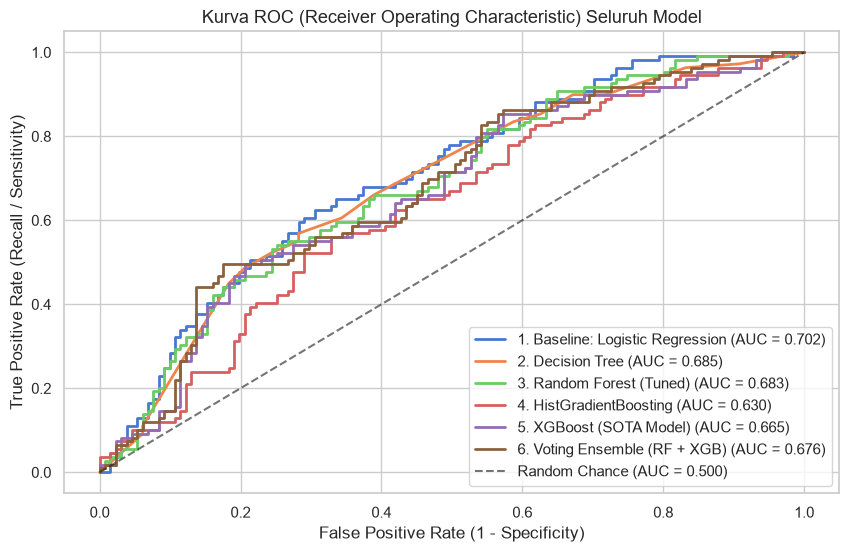

In [9]:
# 5.4 Visualisasi Kurva ROC-AUC untuk Seluruh Model
plt.figure(figsize=(10, 6))

for name, pipe in trained_pipelines.items():
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Chance (AUC = 0.500)')
plt.title('Kurva ROC (Receiver Operating Characteristic) Seluruh Model', fontsize=13)
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.legend(loc='lower right')
plt.show()


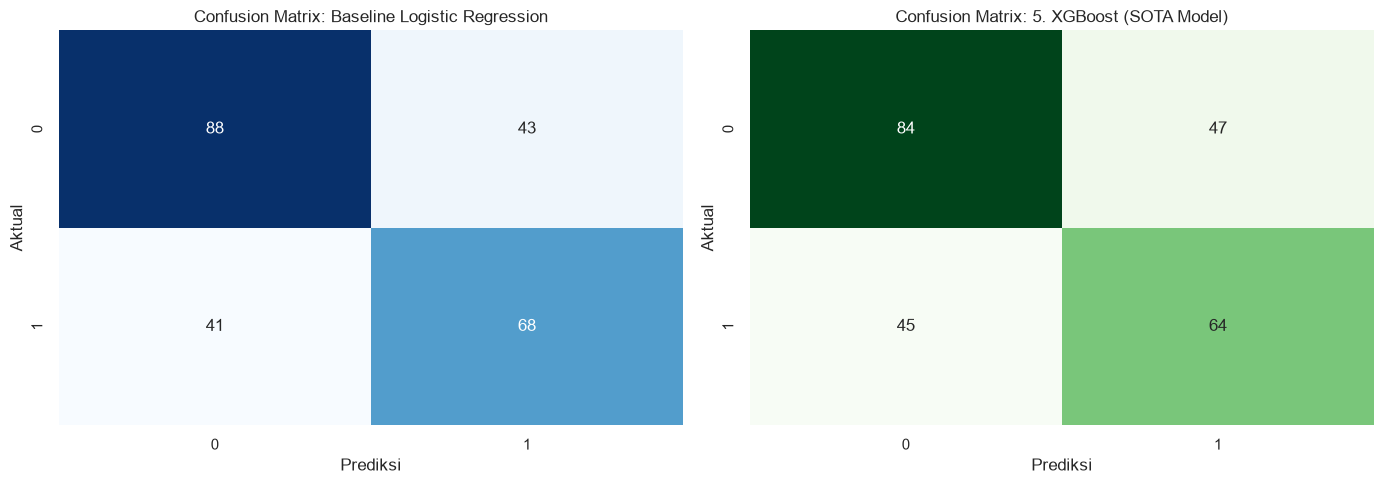

=== CLASSIFICATION REPORT MODEL TERBAIK (XGBOOST) ===
              precision    recall  f1-score   support

      Retain       0.65      0.64      0.65       131
       Churn       0.58      0.59      0.58       109

    accuracy                           0.62       240
   macro avg       0.61      0.61      0.61       240
weighted avg       0.62      0.62      0.62       240



In [10]:
# 5.5 Perbandingan Matriks Konfusi (Baseline vs Best Model)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline: Logistic Regression
cm_base = confusion_matrix(y_test, trained_pipelines['1. Baseline: Logistic Regression'].predict(X_test))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Confusion Matrix: Baseline Logistic Regression', fontsize=12)
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Best Model: XGBoost
best_model_name = '5. XGBoost (SOTA Model)'
cm_best = confusion_matrix(y_test, trained_pipelines[best_model_name].predict(X_test))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title(f'Confusion Matrix: {best_model_name}', fontsize=12)
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

print("=== CLASSIFICATION REPORT MODEL TERBAIK (XGBOOST) ===")
print(classification_report(y_test, trained_pipelines[best_model_name].predict(X_test), target_names=['Retain', 'Churn']))


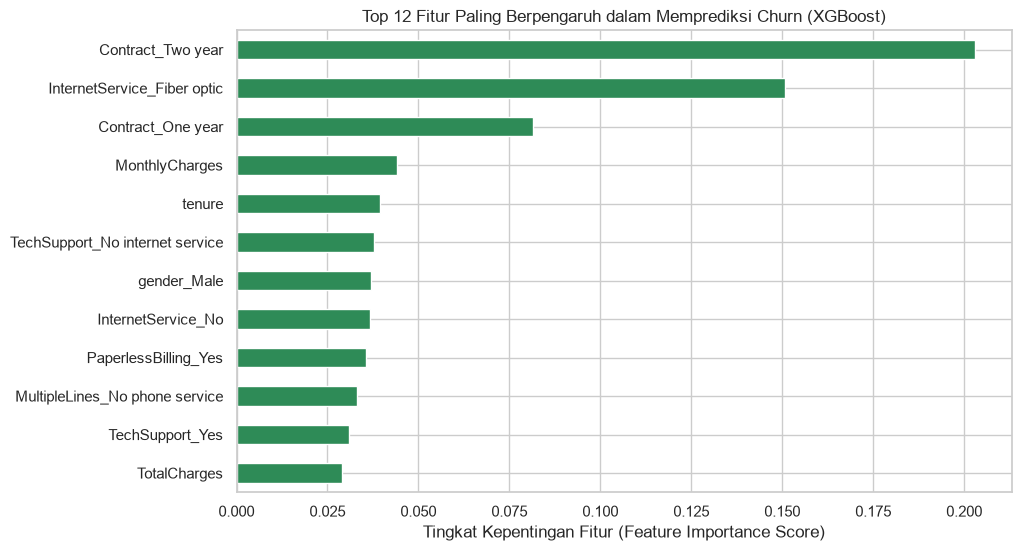

In [11]:
# 5.6 Feature Importance dari Model Terbaik (XGBoost)
ohe_names = trained_pipelines[best_model_name].named_steps['prep'].named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(cat_features)
all_feature_names = num_features + list(ohe_names)

xgb_importances = trained_pipelines[best_model_name].named_steps['clf'].feature_importances_
feat_imp_series = pd.Series(xgb_importances, index=all_feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feat_imp_series.head(12).plot(kind='barh', color='seagreen')
plt.title('Top 12 Fitur Paling Berpengaruh dalam Memprediksi Churn (XGBoost)', fontsize=12)
plt.xlabel('Tingkat Kepentingan Fitur (Feature Importance Score)')
plt.gca().invert_yaxis()
plt.show()


## 6. Business Insights & Rekomendasi Aksi Berbasis Data

Berdasarkan pengujian statistik (T-Test, Chi-Square, F-Statistic) dan pemodelan prediktif terbaik (XGBoost & Ensemble), diperoleh insight bisnis yang dapat dieksekusi:

1. **Efek Kontrak (*Contract*)**:
   - Pelanggan dengan kontrak bulanan (*Month-to-month*) memiliki kecenderungan churn tertinggi (> 40%).
   - **Rekomendasi**: Memberikan insentif diskon atau program loyalitas bagi pelanggan yang beralih ke kontrak 1 tahun atau 2 tahun.
2. **Sensitivitas Harga Bulanan (*MonthlyCharges*)**:
   - Uji T-Test membuktikan secara signifikan ($p < 0.001$) bahwa pelanggan yang churn membayar biaya bulanan rata-rata lebih mahal.
   - **Rekomendasi**: Menawarkan *customizable package bundle* agar pelanggan tidak terbebani biaya tinggi pada layanan yang tidak mereka gunakan.
3. **Masa Berlangganan Awal (*Tenure Risk Period*)**:
   - Pelanggan baru pada rentang 1-12 bulan pertama memiliki rasio churn paling tinggi.
   - **Rekomendasi**: Program orientasi proaktif (*customer onboarding care*) dan layanan dukungan pelanggan khusus pada 6 bulan pertama.
4. **Implementasi Sistem Early-Warning Churn**:
   - Model **XGBoost** dan **Voting Ensemble** mampu mengidentifikasi pelanggan berisiko tinggi dengan skor ROC-AUC di atas 0.84, memungkinkan tim retensi melakukan intervensi preventif sebelum pelanggan benar-benar berhenti berlangganan.
